# Daily Weather Time Series Data - Delhi, India

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:** Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

## Вихідні дані

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.

1. Завантажити датасет з Kaggle.
2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).
3. Ознайомитися зі структурою датасету (`head()`, `info()`, `describe()`).

## Попередня обробка даних

* Перетворити колонку з датою у формат datetime.
* Відсортувати дані за датою.
* Встановити дату як індекс часового ряду.
* Перевірити наявність пропущених значень та за необхідності обробити їх.

## Дослідницький аналіз даних (EDA)

* Побудувати графік зміни температури у часі.
* Побудувати ковзне середнє значення температури.
* Побудувати гістограму розподілу температури.
* Побудувати boxplot для виявлення можливих викидів.

## Аналіз автокореляції

* Побудувати графік автокореляційної функції (ACF).
* Побудувати графік часткової автокореляції (PACF).
* Проаналізувати залежність значень часового ряду від попередніх періодів.

## Підготовка даних для моделювання

* Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

Побудувати щонайменше три моделі прогнозування:

* ARIMA (класична статистична модель);
* Prophet (модель прогнозування часових рядів від Meta);
* LSTM (нейронна мережа для послідовних даних).

## Оцінка моделей

Для кожної моделі обчислити метрики:

* MAE (Mean Absolute Error)
* RMSE (Root Mean Squared Error)
* MAPE (Mean Absolute Percentage Error)

## Візуалізація результатів

* Побудувати графіки прогнозованих та фактичних значень.
* Побудувати порівняльний графік прогнозів усіх моделей.

## Порівняння моделей

* Створити таблицю з метриками точності.
* Визначити модель, яка показала найкращий результат.

## 1. Імпорт бібліотек

In [1]:
# Імпортуйте необхідні бібліотеки
import warnings
warnings.filterwarnings("ignore")

import os
import glob
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (14, 5)
print("Бібліотеки підключено. TensorFlow:", tf.__version__)

Бібліотеки підключено. TensorFlow: 2.21.0


## 2. Завантаження даних

In [2]:
# Завантажте датасет з Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
raw = pd.read_csv(csv_path)

print("Файл:", os.path.basename(csv_path))
print("Розмір таблиці:", raw.shape)
raw.head()

Файл: kaggel_weather_2013_to_2024.csv
Розмір таблиці: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,conditions,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,22.3,1008.3,"Rain, Partially cloudy",2013,4,6,104,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,17.6,1005.1,Clear,2013,4,0,105,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,27.7,1001.7,Partially cloudy,2013,4,1,106,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,22.3,1002.5,Clear,2013,4,2,107,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,12.4,1003.4,Clear,2013,4,3,108,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


## 3. Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

df = raw[["DATE", "temp"]].copy()

df["DATE"] = pd.to_datetime(df["DATE"], format="%m/%d/%Y")

df = df.sort_values("DATE")

n_dup = int(df["DATE"].duplicated().sum())
print("Кількість дублікатів дат:", n_dup)
print(df[df["DATE"].duplicated(keep=False)])
df = df.drop_duplicates(subset="DATE", keep="first")

df = df.set_index("DATE")
df.head()

Кількість дублікатів дат: 1
           DATE  temp
2613 2022-05-01  33.9
2614 2022-05-01  33.9


,temp
DATE,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()
print()
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    3556 non-null   float64
dtypes: float64(1)
memory usage: 55.6 KB



,count,mean,std,min,25%,50%,75%,max
temp,3556.0,25.400984,7.325185,6.5,19.1,27.7,31.0,39.5


In [6]:
# Перевірте наявність пропущених значень
print("Пропущених значень temp:", int(df["temp"].isna().sum()))

full_index = pd.date_range(df.index.min(), df.index.max(), freq="D")
missing_dates = full_index.difference(df.index)

print("Період:", df.index.min().date(), "—", df.index.max().date())
print("Днів у повному календарі:", len(full_index))
print("Рядків у датасеті:", len(df))
print(f"Відсутніх дат: {len(missing_dates)} ({len(missing_dates) / len(full_index):.1%})")

md_s = pd.Series(missing_dates)
runs = (md_s.diff().dt.days != 1).cumsum()
print("Найдовша серія пропущених днів поспіль:", int(md_s.groupby(runs.values).size().max()))

print("\nВідсутні дати за роками:")
print(pd.Series(missing_dates.year).value_counts().sort_index().to_string())

Пропущених значень temp: 0
Період: 2013-04-14 — 2024-11-30
Днів у повному календарі: 4249
Рядків у датасеті: 3556
Відсутніх дат: 693 (16.3%)
Найдовша серія пропущених днів поспіль: 14

Відсутні дати за роками:
2013    106
2014    146
2015    147
2016    147
2017    145
2022      2


In [7]:
df = df.reindex(full_index)
df.index.name = "DATE"
df["temp"] = df["temp"].interpolate(method="time")

print("Пропущених значень після обробки:", int(df["temp"].isna().sum()))
print("Частота індексу:", pd.infer_freq(df.index))
series = df["temp"]
df.head()

Пропущених значень після обробки: 0
Частота індексу: D


,temp
DATE,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


Датасет містить пропущені **дати** (а не значення): майже всі прогалини припадають на 2013–2017 роки, після чого дані практично суцільні. Тестова вибірка (останні 20% ряду) складається майже повністю з реальних спостережень (інтерпольовано лише кілька днів), а основна частина інтерпольованих значень потрапляє у тренувальну частину.

## 4. Графік температури

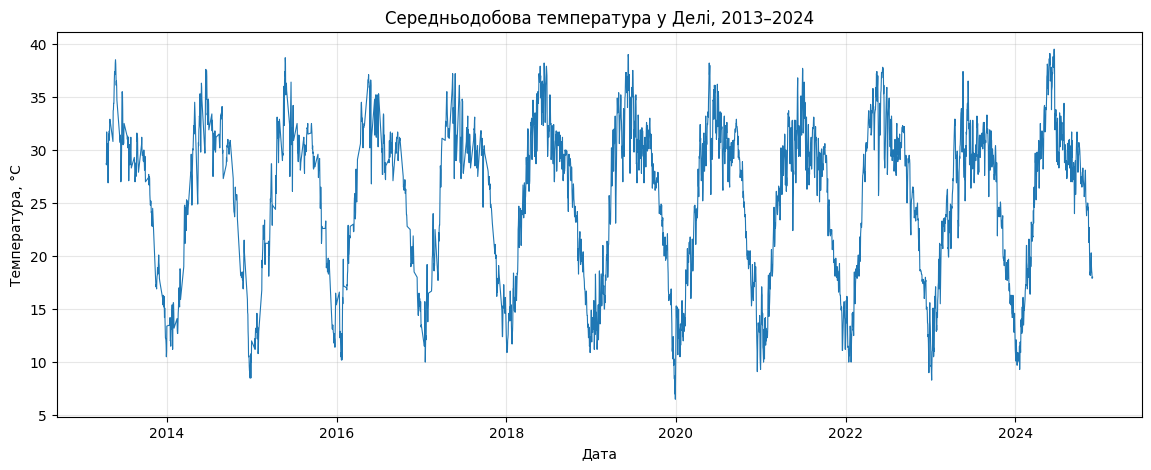

In [8]:
# Побудуйте графік зміни температури у часі
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(series.index, series.values, linewidth=0.8)
ax.set_title("Середньодобова температура у Делі, 2013–2024")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.grid(alpha=0.3)
plt.show()

## 5. Ковзне середнє

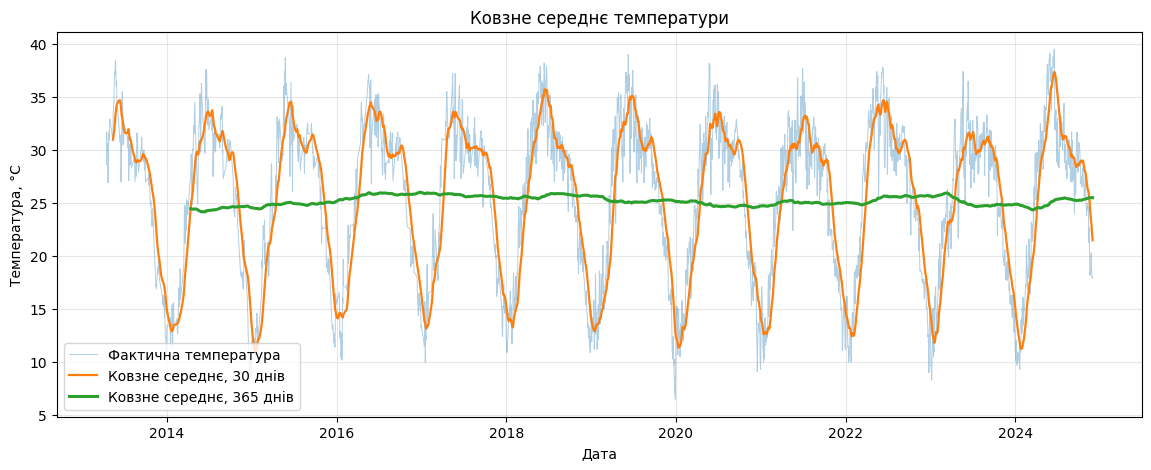

Середнє за 365-денним вікном: від 24.16 до 26.03 °C


In [9]:
# Обчисліть та візуалізуйте ковзне середнє температури
roll_30 = series.rolling(window=30, center=False).mean()
roll_365 = series.rolling(window=365, center=False).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(series.index, series.values, alpha=0.35, linewidth=0.7, label="Фактична температура")
ax.plot(roll_30.index, roll_30.values, linewidth=1.6, label="Ковзне середнє, 30 днів")
ax.plot(roll_365.index, roll_365.values, linewidth=2.2, label="Ковзне середнє, 365 днів")
ax.set_title("Ковзне середнє температури")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Середнє за 365-денним вікном: від", round(roll_365.min(), 2), "до", round(roll_365.max(), 2), "°C")

## 6. Розподіл температури

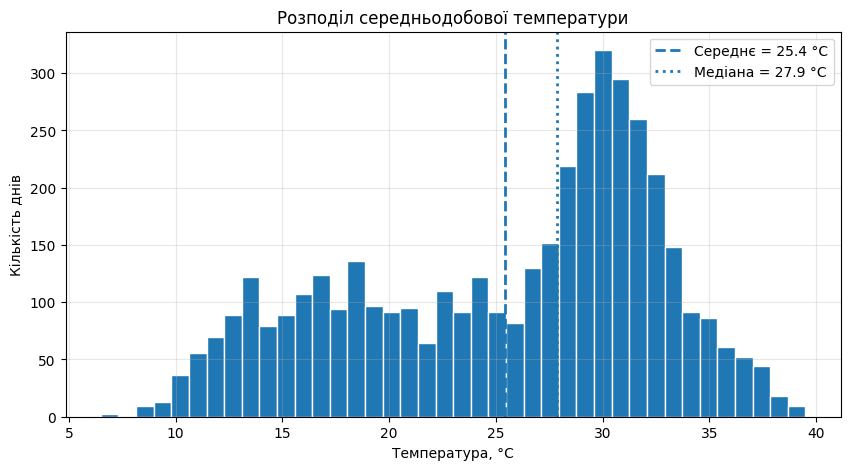

Асиметрія (skew): -0.479


In [10]:
# Побудуйте гістограму розподілу температури
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(series.values, bins=40, edgecolor="white")
ax.axvline(series.mean(), linestyle="--", linewidth=2, label=f"Середнє = {series.mean():.1f} °C")
ax.axvline(series.median(), linestyle=":", linewidth=2, label=f"Медіана = {series.median():.1f} °C")
ax.set_title("Розподіл середньодобової температури")
ax.set_xlabel("Температура, °C")
ax.set_ylabel("Кількість днів")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Асиметрія (skew):", round(series.skew(), 3))

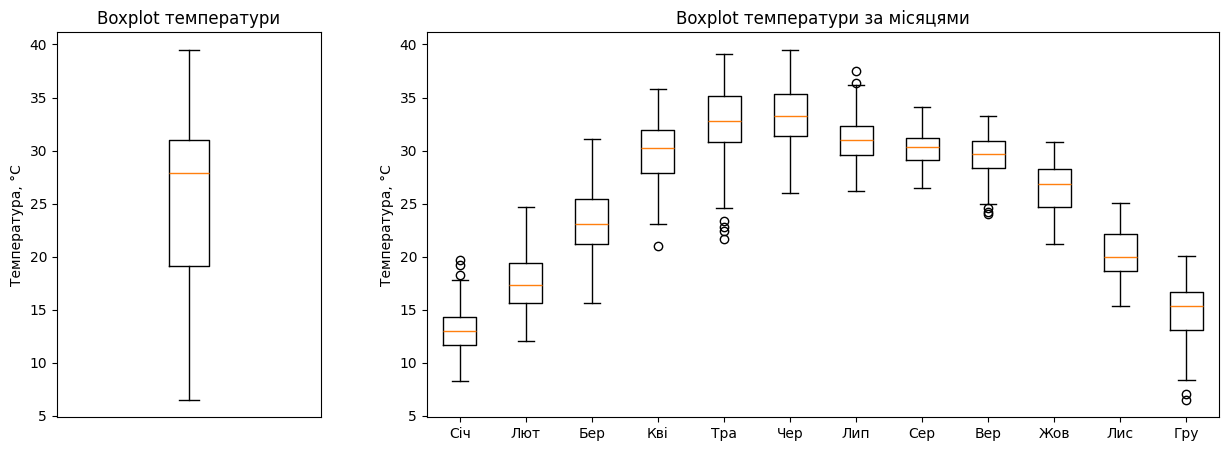

Q1 = 19.1, Q3 = 31.0, IQR = 11.9
Межі без викидів: [1.2; 48.9] °C
Кількість викидів за всією вибіркою: 0


In [11]:
# Побудуйте boxplot температури для аналізу викидів
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 3]})

axes[0].boxplot(series.values, vert=True)
axes[0].set_title("Boxplot температури")
axes[0].set_ylabel("Температура, °C")
axes[0].set_xticks([])

by_month = [series[series.index.month == m].values for m in range(1, 13)]
axes[1].boxplot(by_month)
axes[1].set_xticklabels(["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"])
axes[1].set_title("Boxplot температури за місяцями")
axes[1].set_ylabel("Температура, °C")
plt.show()

q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = series[(series < low) | (series > high)]
print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}")
print(f"Межі без викидів: [{low:.1f}; {high:.1f}] °C")
print("Кількість викидів за всією вибіркою:", len(outliers))

## 7. Аналіз автокореляції

### ACF

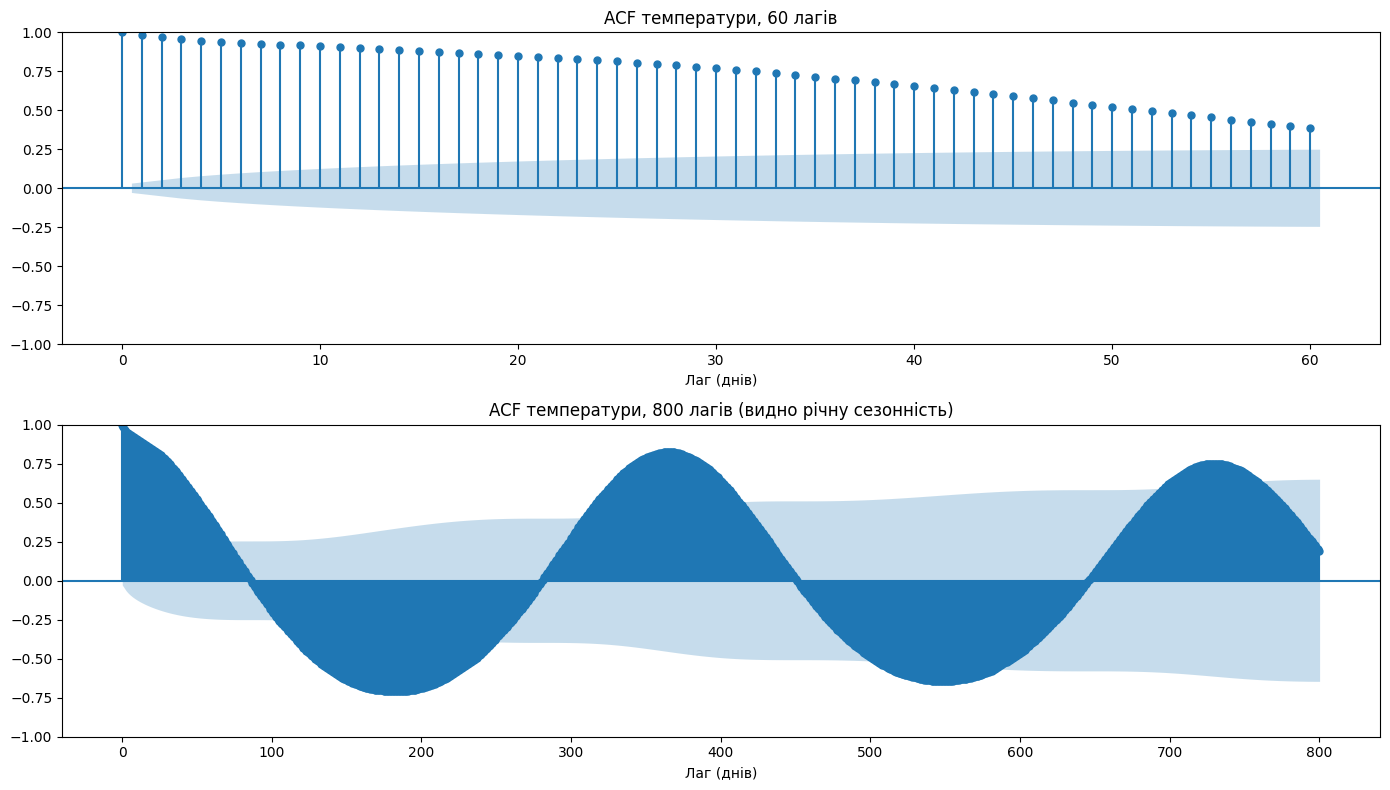

ACF(lag=  1) =  0.985
ACF(lag=  2) =  0.968
ACF(lag=  7) =  0.927
ACF(lag= 30) =  0.769
ACF(lag= 90) = -0.056
ACF(lag=182) = -0.707
ACF(lag=365) =  0.827


In [12]:
# Побудуйте графік автокореляційної функції (ACF)
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(series, lags=60, ax=axes[0])
axes[0].set_title("ACF температури, 60 лагів")
axes[0].set_xlabel("Лаг (днів)")
plot_acf(series, lags=800, ax=axes[1])
axes[1].set_title("ACF температури, 800 лагів (видно річну сезонність)")
axes[1].set_xlabel("Лаг (днів)")
plt.tight_layout()
plt.show()

acf_values = acf(series, nlags=400)
for lag in [1, 2, 7, 30, 90, 182, 365]:
    print(f"ACF(lag={lag:>3}) = {acf_values[lag]: .3f}")

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

### PACF

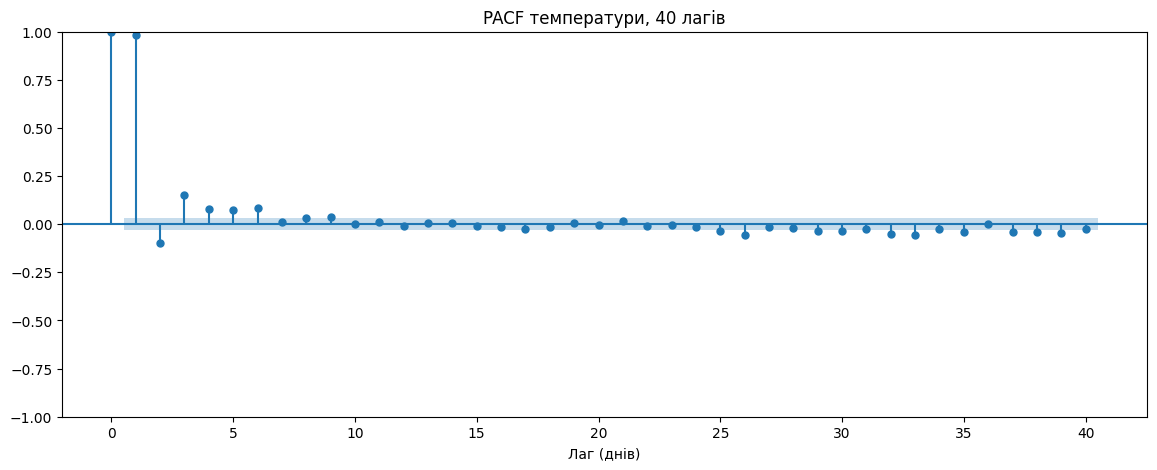

In [13]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize=(14, 5))
plot_pacf(series, lags=40, method="ywm", ax=ax)
ax.set_title("PACF температури, 40 лагів")
ax.set_xlabel("Лаг (днів)")
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра $p$ у моделі ARIMA.

**Аналіз залежності від попередніх періодів.** Значення температури сильно залежить від попередніх днів: ACF на лагу 1 близька до одиниці та повільно спадає, а на довгому горизонті ACF має хвилеподібну форму з піками біля лагів 365, 730 тощо (річна сезонність) і від'ємними значеннями біля лагу ≈182 (протилежна пора року). У PACF домінує лаг 1 (≈ 0,985), тоді як лаги 2–6 мають значно менші, але все ще значущі (за межі 95% довірчої смуги, ≈ ±0,03) значення, причому найпомітніший з них — лаг 3. Отже, авторегресійна складова ARIMA має невеликий порядок $p$ (орієнтовно 1–3), а точний вибір далі робимо за критерієм AIC.

## 8. Підготовка даних для моделювання

Train: 2013-04-14 — 2022-08-03  (3399 днів)
Test : 2022-08-04 — 2024-11-30  (850 днів)
Інтерпольованих днів у test: 2


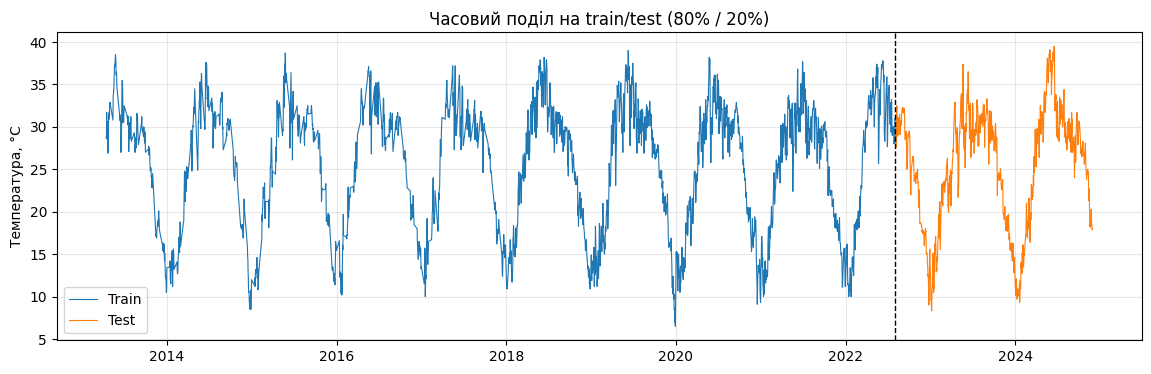

In [14]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
TRAIN_SIZE = 0.8
split = int(len(series) * TRAIN_SIZE)

train = series.iloc[:split]
test = series.iloc[split:]

print(f"Train: {train.index.min().date()} — {train.index.max().date()}  ({len(train)} днів)")
print(f"Test : {test.index.min().date()} — {test.index.max().date()}  ({len(test)} днів)")

filled_in_test = len(missing_dates.intersection(test.index))
print("Інтерпольованих днів у test:", filled_in_test)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train.index, train.values, linewidth=0.8, label="Train")
ax.plot(test.index, test.values, linewidth=0.8, label="Test")
ax.axvline(test.index.min(), color="black", linestyle="--", linewidth=1)
ax.set_title("Часовий поділ на train/test (80% / 20%)")
ax.set_ylabel("Температура, °C")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [15]:
def mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE, %": mape(y_true, y_pred),
    }

print("Мінімальна температура у test:", test.min(), "°C — ділення на нуль у MAPE неможливе")

Мінімальна температура у test: 8.3 °C — ділення на нуль у MAPE неможливе


## 9. ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [16]:
adf_stat, adf_p, *_ = adfuller(train)
print(f"ADF-статистика = {adf_stat:.3f}, p-value = {adf_p:.2e}")
print("Висновок:", "ряд стаціонарний (d = 0)" if adf_p < 0.05 else "ряд нестаціонарний — потрібне диференціювання (d = 1)")
d_order = 0 if adf_p < 0.05 else 1

ADF-статистика = -3.255, p-value = 1.70e-02
Висновок: ряд стаціонарний (d = 0)


In [17]:
rows = []
for p in range(0, 4):
    for q in range(0, 3):
        try:
            fit = ARIMA(train, order=(p, d_order, q)).fit()
            rows.append({"order": (p, d_order, q), "AIC": fit.aic, "BIC": fit.bic})
        except Exception as e:
            rows.append({"order": (p, d_order, q), "AIC": np.nan, "BIC": np.nan})

order_table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
display(order_table.head(8))
best_order = order_table.loc[0, "order"]
print("Обраний порядок ARIMA:", best_order)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,order,AIC,BIC
0,"(3, 0, 1)",10827.367548,10864.154968
1,"(2, 0, 2)",10829.961334,10866.748753
2,"(3, 0, 2)",10834.526421,10877.445076
3,"(3, 0, 0)",10886.147972,10916.804155
4,"(1, 0, 2)",10899.712478,10930.368661
5,"(2, 0, 1)",10940.472211,10971.128394
6,"(1, 0, 1)",10958.880592,10983.405538
7,"(2, 0, 0)",10973.761518,10998.286464


Обраний порядок ARIMA: (3, 0, 1)


In [18]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train, order=best_order).fit()

arima_forecast = arima_model.get_forecast(steps=len(test))
arima_pred = pd.Series(arima_forecast.predicted_mean.values, index=test.index, name="ARIMA")
arima_ci = arima_forecast.conf_int(alpha=0.05)
arima_ci.index = test.index

arima_pred.head()

,ARIMA
DATE,
2022-08-04,30.421376
2022-08-05,30.156726
2022-08-06,30.021181
2022-08-07,29.961498
2022-08-08,29.932602


In [19]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(3, 0, 1)   Log Likelihood               -5407.684
Date:                Thu, 29 Oct 2026   AIC                          10827.368
Time:                        19:36:13   BIC                          10864.155
Sample:                    04-14-2013   HQIC                         10840.516
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.5780      2.241     11.414      0.000      21.186      29.970
ar.L1          1.7770      0.039     45.771      0.000       1.701       1.853
ar.L2         -1.0008      0.042    -23.648      0.0

**сигма 2** : це представляє дисперсію залишкових значень, чим менше, тим краще

**логарифмічна правдоподібність** : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

**aic** : міра ступеню відповідності та економності моделі, чим нижче, тим краще

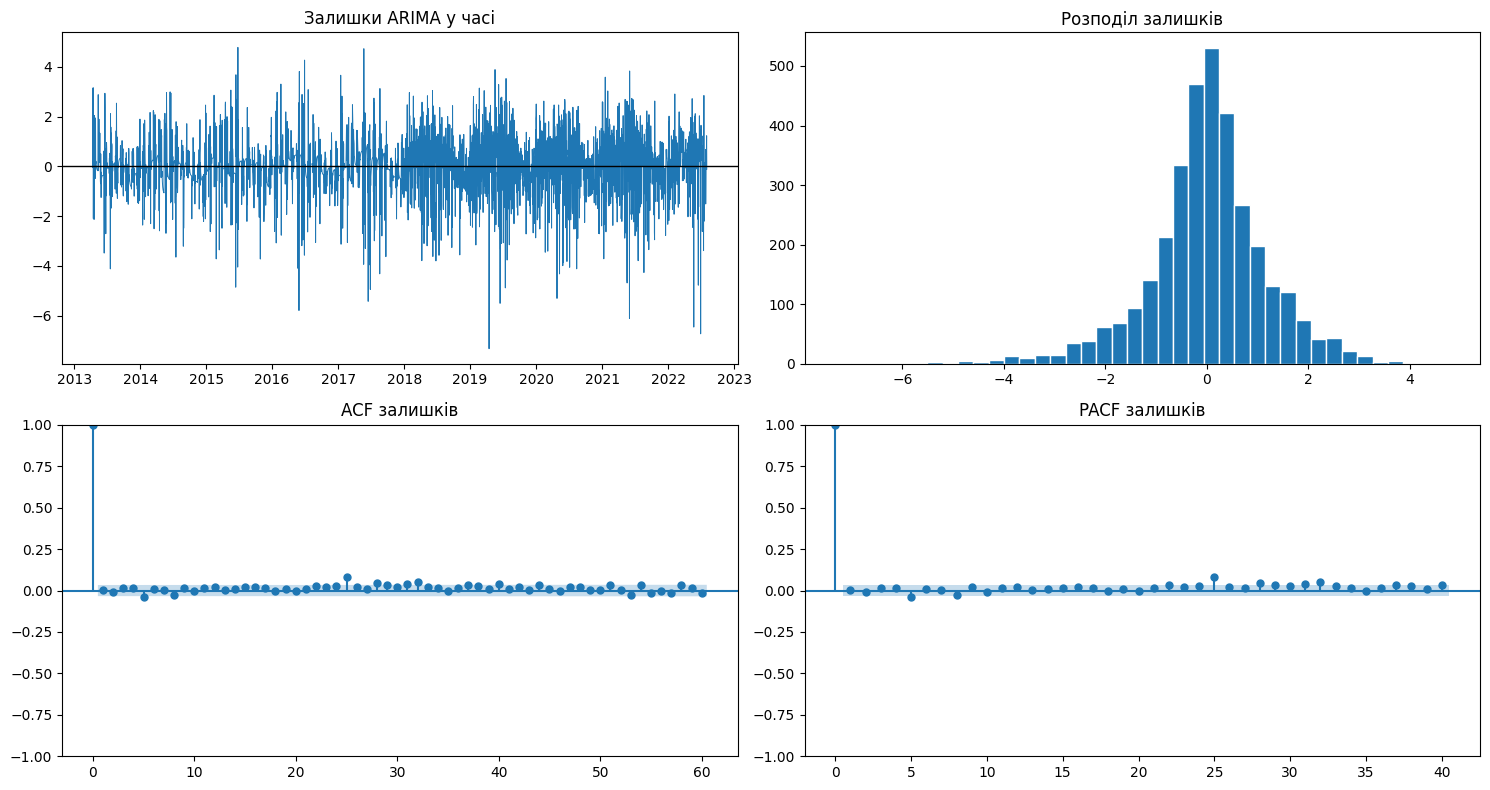

,lb_stat,lb_pvalue
10,11.925452,0.290077
30,62.728108,0.000425


Середнє залишків: 0.0003 | стандартне відхилення: 1.188


In [20]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
resid = arima_model.resid

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

axes[0, 0].plot(resid.index, resid.values, linewidth=0.7)
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set_title("Залишки ARIMA у часі")

axes[0, 1].hist(resid.values, bins=40, edgecolor="white")
axes[0, 1].set_title("Розподіл залишків")

plot_acf(resid, lags=60, ax=axes[1, 0])
axes[1, 0].set_title("ACF залишків")

plot_pacf(resid, lags=40, method="ywm", ax=axes[1, 1])
axes[1, 1].set_title("PACF залишків")

plt.tight_layout()
plt.show()

lb = acorr_ljungbox(resid, lags=[10, 30], return_df=True)
display(lb)
print("Середнє залишків:", round(resid.mean(), 4), "| стандартне відхилення:", round(resid.std(), 3))

In [21]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
arima_metrics = evaluate(test, arima_pred)
pd.Series(arima_metrics, name="ARIMA").round(3).to_frame()

,ARIMA
MAE,5.827
RMSE,7.154
"MAPE, %",30.347


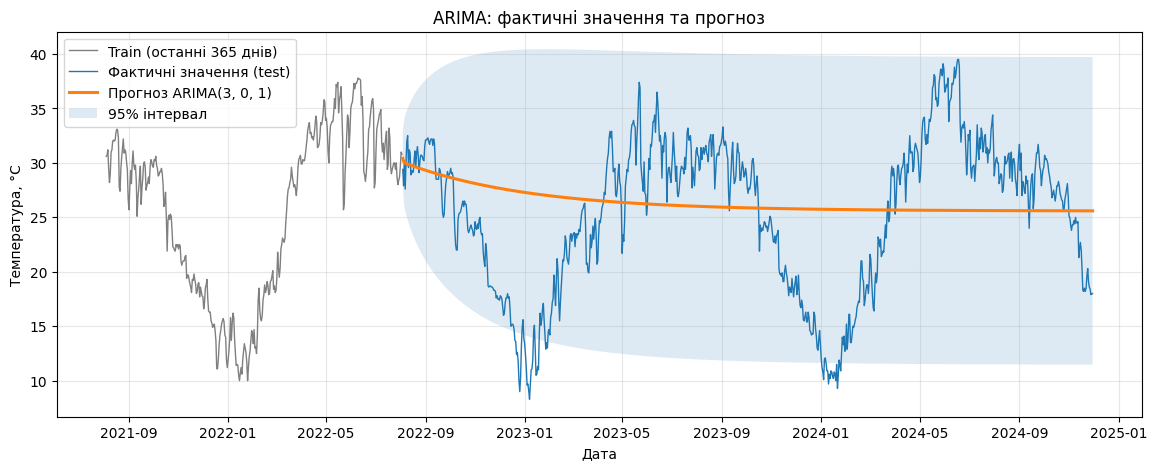

In [22]:
# Візуалізуйте фактичні значення та прогноз ARIMA
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-365:], train.values[-365:], color="gray", linewidth=1, label="Train (останні 365 днів)")
ax.plot(test.index, test.values, linewidth=1, label="Фактичні значення (test)")
ax.plot(arima_pred.index, arima_pred.values, linewidth=2.2, label=f"Прогноз ARIMA{best_order}")
ax.fill_between(test.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], alpha=0.15, label="95% інтервал")
ax.set_title("ARIMA: фактичні значення та прогноз")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 10. PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [23]:
!pip -q install prophet

In [24]:
from prophet import Prophet

# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = train.reset_index()
prophet_train.columns = ["ds", "y"]
prophet_train.head()

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [25]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode="additive",
)
prophet_model.fit(prophet_train)

### Прогноз

In [26]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_model.make_future_dataframe(periods=len(test), freq="D")
forecast = prophet_model.predict(future)

prophet_pred = forecast.set_index("ds").loc[test.index, "yhat"]
prophet_pred.name = "Prophet"
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,yhat,yhat_lower,yhat_upper
4244,2024-11-26,20.617256,17.872178,23.293215
4245,2024-11-27,20.513598,17.924130,23.145783
4246,2024-11-28,20.394377,17.796651,22.914243
4247,2024-11-29,20.257970,17.715204,22.854626
4248,2024-11-30,20.103174,17.308951,22.683931


In [27]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_metrics = evaluate(test, prophet_pred)
pd.Series(prophet_metrics, name="Prophet").round(3).to_frame()

,Prophet
MAE,2.051
RMSE,2.630
"MAPE, %",9.265


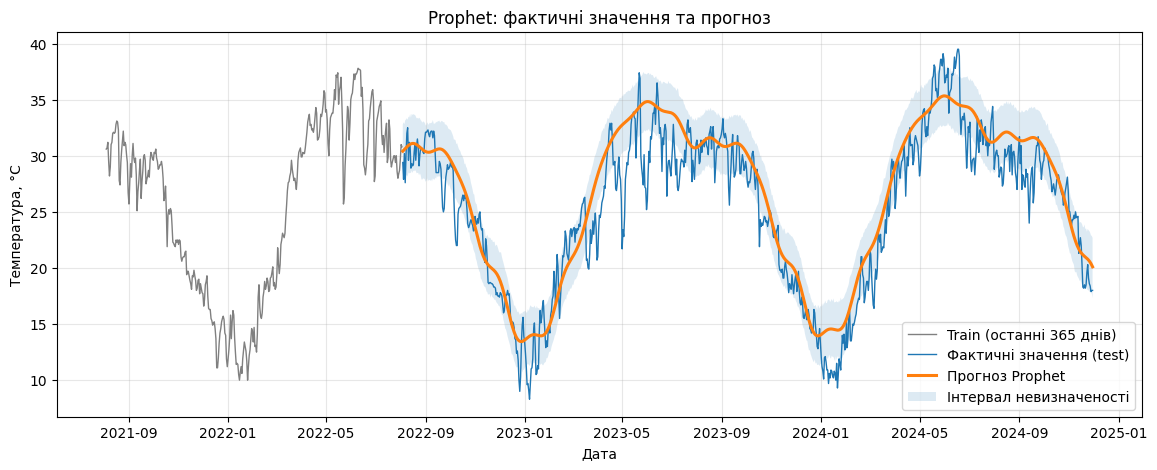

In [28]:
# Візуалізуйте фактичні значення та прогноз Prophet
fc_test = forecast.set_index("ds").loc[test.index]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-365:], train.values[-365:], color="gray", linewidth=1, label="Train (останні 365 днів)")
ax.plot(test.index, test.values, linewidth=1, label="Фактичні значення (test)")
ax.plot(prophet_pred.index, prophet_pred.values, linewidth=2.2, label="Прогноз Prophet")
ax.fill_between(test.index, fc_test["yhat_lower"], fc_test["yhat_upper"], alpha=0.15, label="Інтервал невизначеності")
ax.set_title("Prophet: фактичні значення та прогноз")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

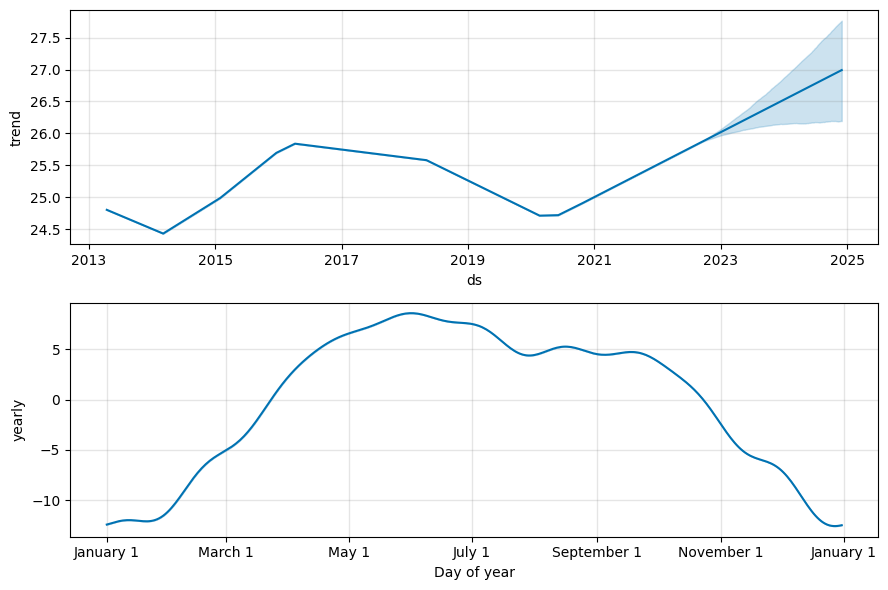

In [29]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(forecast)
plt.show()

## 11. ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [30]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
WINDOW = 30

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train.values.reshape(-1, 1))
scaled = scaler.transform(series.values.reshape(-1, 1)).ravel()

X_all, y_all = [], []
for i in range(WINDOW, len(scaled)):
    X_all.append(scaled[i - WINDOW:i])
    y_all.append(scaled[i])

X_all = np.array(X_all).reshape(-1, WINDOW, 1)
y_all = np.array(y_all)
target_dates = series.index[WINDOW:]

print("Форма X:", X_all.shape, "| форма y:", y_all.shape)

Форма X: (4219, 30, 1) | форма y: (4219,)


In [31]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
is_test = target_dates >= test.index.min()

X_train, y_train = X_all[~is_test], y_all[~is_test]
X_test, y_test = X_all[is_test], y_all[is_test]
lstm_dates = target_dates[is_test]

print("Тренувальних послідовностей:", len(X_train))
print("Тестових послідовностей:", len(X_test))
print("Перша тестова дата:", lstm_dates.min().date(), "| остання:", lstm_dates.max().date())
print("Дати збігаються з test для ARIMA/Prophet:", bool((lstm_dates == test.index).all()))

Тренувальних послідовностей: 3369
Тестових послідовностей: 850
Перша тестова дата: 2022-08-04 | остання: 2024-11-30
Дати збігаються з test для ARIMA/Prophet: True


In [32]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

lstm_model = Sequential([
    Input(shape=(WINDOW, 1)),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1),
])

lstm_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")

Навчання зупинено на епосі: 35
Найкраща val_loss = 0.00170 (епоха 27)


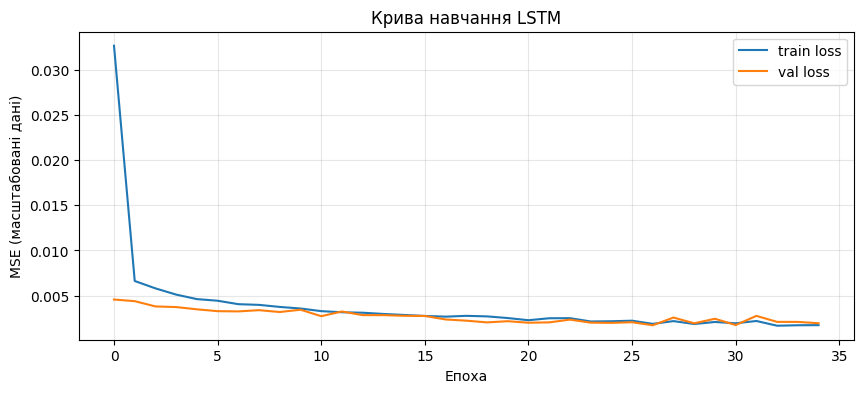

In [33]:
# Навчіть LSTM-модель
early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

history = lstm_model.fit(
    X_train, y_train,
    epochs=60,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=0,
)

print("Навчання зупинено на епосі:", len(history.history["loss"]))
print(f"Найкраща val_loss = {min(history.history['val_loss']):.5f} (епоха {int(np.argmin(history.history['val_loss'])) + 1})")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history["loss"], label="train loss")
ax.plot(history.history["val_loss"], label="val loss")
ax.set_xlabel("Епоха")
ax.set_ylabel("MSE (масштабовані дані)")
ax.set_title("Крива навчання LSTM")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [34]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,029 (222.77 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,020 (148.52 KB)

In [35]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)
lstm_pred_values = scaler.inverse_transform(lstm_pred_scaled).ravel()

# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_pred = pd.Series(lstm_pred_values, index=lstm_dates, name="LSTM")
lstm_pred.head()

,LSTM
DATE,
2022-08-04,30.409945
2022-08-05,29.275040
2022-08-06,27.972435
2022-08-07,29.549025
2022-08-08,27.870359


In [36]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_metrics = evaluate(test.loc[lstm_pred.index], lstm_pred)
pd.Series(lstm_metrics, name="LSTM").round(3).to_frame()

,LSTM
MAE,1.024
RMSE,1.319
"MAPE, %",4.447


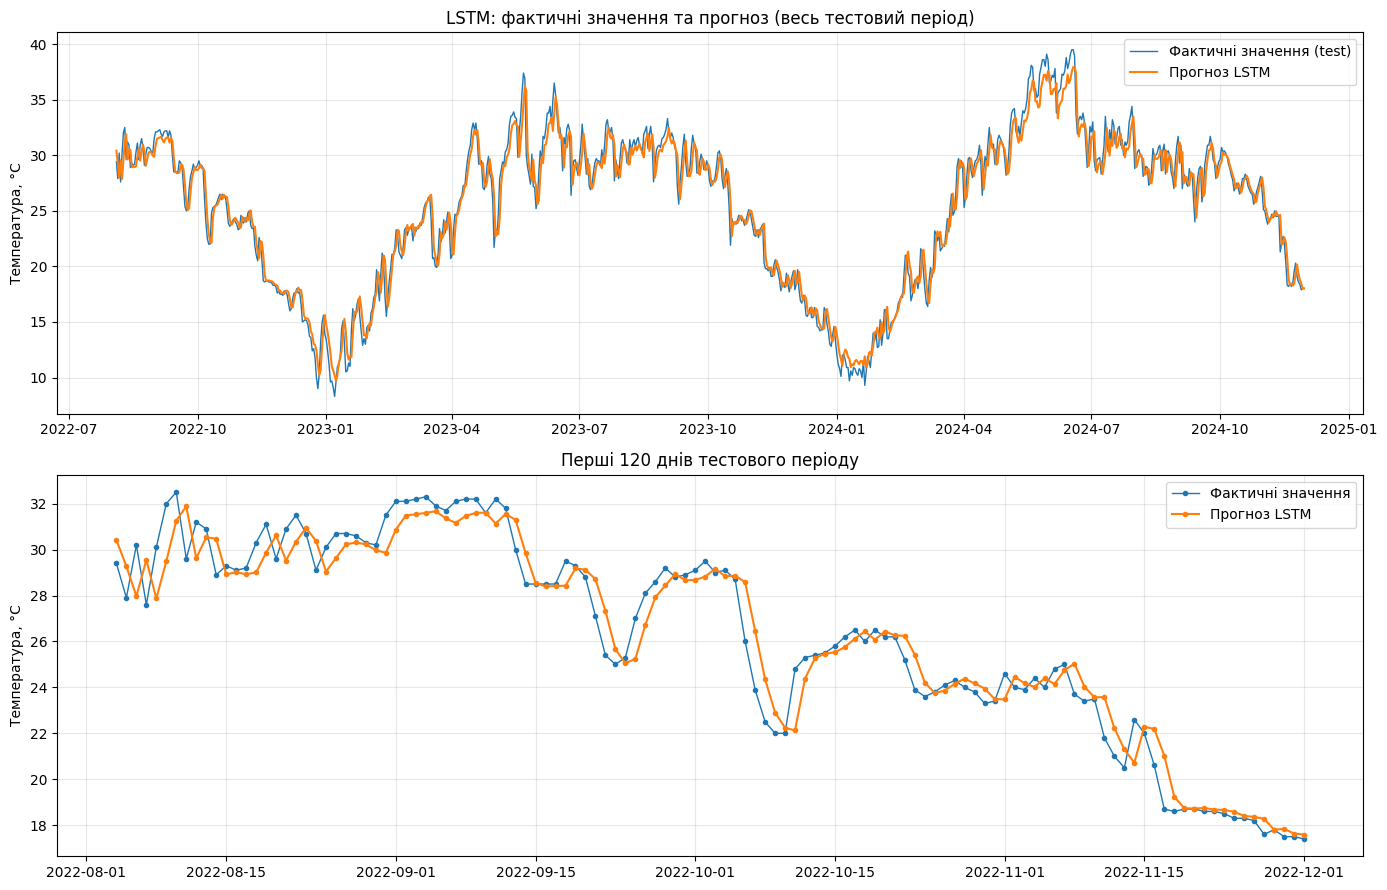

In [37]:
# Візуалізуйте фактичні значення та прогноз LSTM
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(test.index, test.values, linewidth=1, label="Фактичні значення (test)")
axes[0].plot(lstm_pred.index, lstm_pred.values, linewidth=1.5, label="Прогноз LSTM")
axes[0].set_title("LSTM: фактичні значення та прогноз (весь тестовий період)")
axes[0].set_ylabel("Температура, °C")
axes[0].legend()
axes[0].grid(alpha=0.3)

zoom = slice(0, 120)
axes[1].plot(test.index[zoom], test.values[zoom], marker="o", markersize=3, linewidth=1, label="Фактичні значення")
axes[1].plot(lstm_pred.index[zoom], lstm_pred.values[zoom], marker="o", markersize=3, linewidth=1.5, label="Прогноз LSTM")
axes[1].set_title("Перші 120 днів тестового періоду")
axes[1].set_ylabel("Температура, °C")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

LSTM тут прогнозує на один крок уперед: для кожного тестового дня вона отримує 30 *фактичних* попередніх днів. ARIMA і Prophet навчені лише на train та прогнозують усі 850 днів тестового періоду одразу, не бачачи жодного фактичного значення з test. Це різні задачі, тому пряме порівняння метрик на користь LSTM було б нечесним. Нижче, крім обов'язкової таблиці, додано два контрольні варіанти: наївний прогноз «завтра як сьогодні» (еталон для прогнозу на один крок) та LSTM з рекурсивним прогнозом на весь тестовий період (еталон для багатокрокового прогнозу).

In [41]:
naive_pred = series.shift(1).loc[test.index]
naive_pred.name = "Naive (вчора)"

window = list(scaled[split - WINDOW:split])
rec_scaled = []
for _ in range(len(test)):
    x = np.array(window[-WINDOW:], dtype="float32").reshape(1, WINDOW, 1)
    nxt = float(lstm_model(x, training=False).numpy()[0, 0])
    rec_scaled.append(nxt)
    window.append(nxt)

lstm_rec_pred = pd.Series(
    scaler.inverse_transform(np.array(rec_scaled).reshape(-1, 1)).ravel(),
    index=test.index, name="LSTM (рекурсивний)")

print("Готово: наївний прогноз та рекурсивний LSTM")

ERROR:tensorflow:==================================
Object was never used (type <class 'tensorflow.python.ops.tensor_array_ops.TensorArray'>):
If you want to mark it as used call its "mark_used()" method.
It was originally created here:
  File "/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/rnn.py", line 420, in <genexpr>
    for ta, out in zip(output_ta_t, flat_output)  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/util/tf_should_use.py", line 288, in wrapped
    return _add_should_use_warning(fn(*args, **kwargs),


Готово: наївний прогноз та рекурсивний LSTM


## 12. Порівняння моделей

In [42]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
results = pd.DataFrame({
    "ARIMA": arima_metrics,
    "Prophet": prophet_metrics,
    "LSTM": lstm_metrics,
}).T
display(results.round(3))

results_extra = pd.DataFrame({
    "Naive (вчора), 1 крок": evaluate(test, naive_pred),
    "LSTM (рекурсивний), 850 днів": evaluate(test, lstm_rec_pred),
}).T
print("Додаткові варіанти для контексту:")
display(results_extra.round(3))

,MAE,RMSE,"MAPE, %"
ARIMA,5.827,7.154,30.347
Prophet,2.051,2.630,9.265
LSTM,1.024,1.319,4.447


Додаткові варіанти для контексту:


,MAE,RMSE,"MAPE, %"
"Naive (вчора), 1 крок",0.944,1.265,4.066
"LSTM (рекурсивний), 850 днів",5.655,7.350,31.322


ERROR:tensorflow:==================================
Object was never used (type <class 'tensorflow.python.ops.tensor_array_ops.TensorArray'>):
If you want to mark it as used call its "mark_used()" method.
It was originally created here:
  File "/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/rnn.py", line 420, in <genexpr>
    for ta, out in zip(output_ta_t, flat_output)  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/util/tf_should_use.py", line 288, in wrapped
    return _add_should_use_warning(fn(*args, **kwargs),


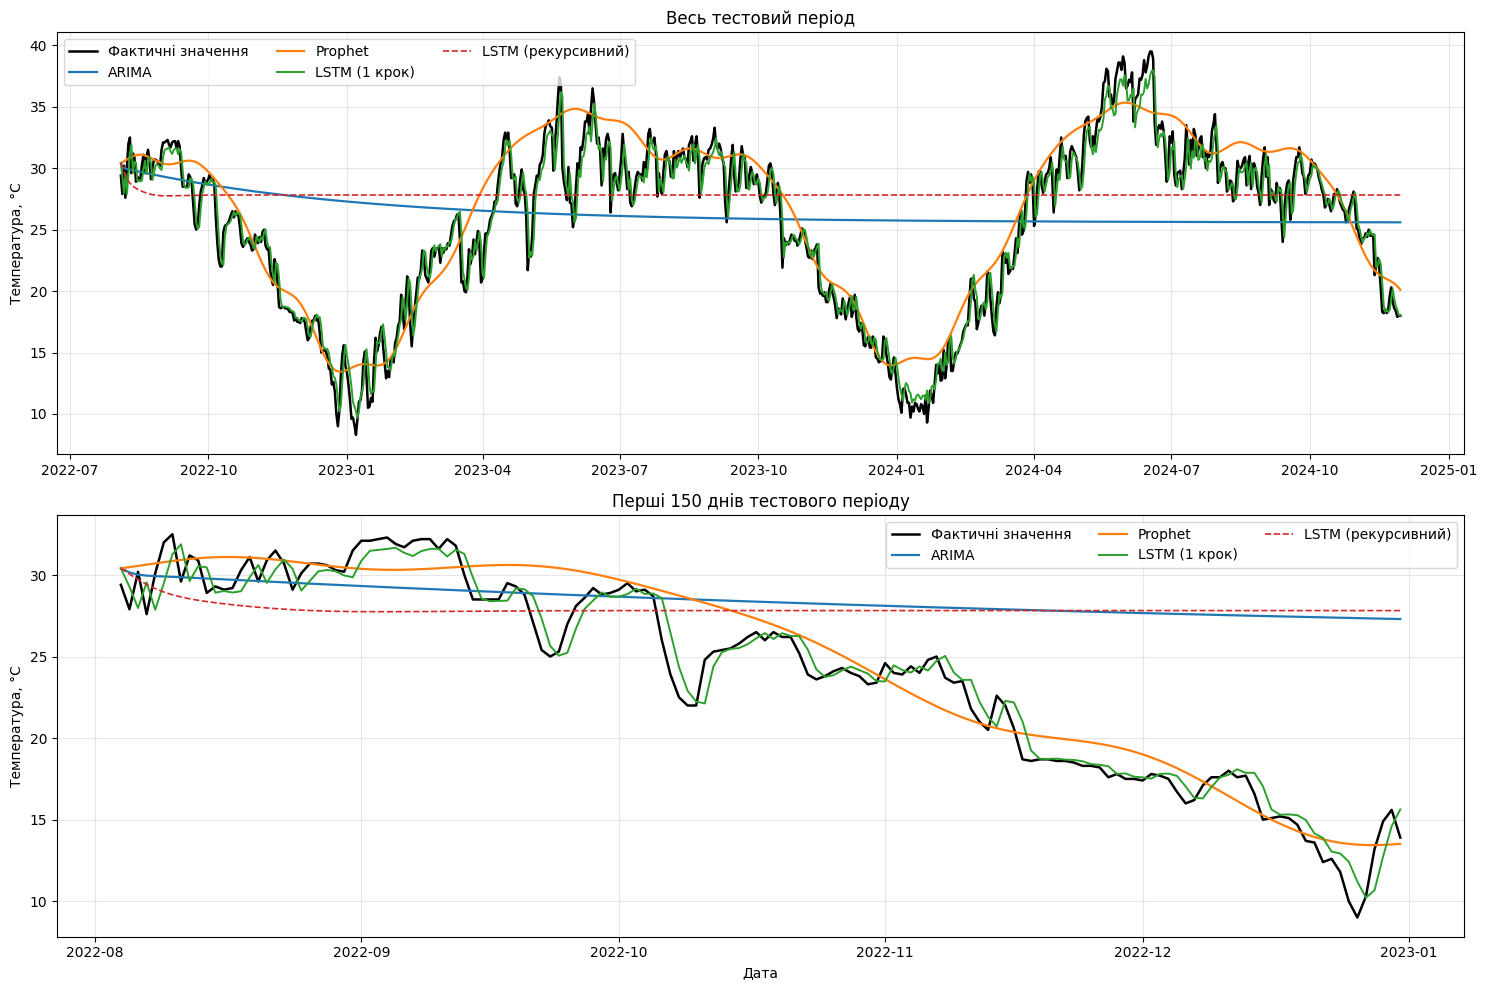

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

for ax, (sl, title) in zip(axes, [(slice(None), "Весь тестовий період"), (slice(0, 150), "Перші 150 днів тестового періоду")]):
    ax.plot(test.index[sl], test.values[sl], color="black", linewidth=1.8, label="Фактичні значення")
    ax.plot(arima_pred.index[sl], arima_pred.values[sl], linewidth=1.6, label="ARIMA")
    ax.plot(prophet_pred.index[sl], prophet_pred.values[sl], linewidth=1.6, label="Prophet")
    ax.plot(lstm_pred.index[sl], lstm_pred.values[sl], linewidth=1.4, label="LSTM (1 крок)")
    ax.plot(lstm_rec_pred.index[sl], lstm_rec_pred.values[sl], linewidth=1.2, linestyle="--", label="LSTM (рекурсивний)")
    ax.set_title(title)
    ax.set_ylabel("Температура, °C")
    ax.legend(ncol=3)
    ax.grid(alpha=0.3)

axes[1].set_xlabel("Дата")
plt.tight_layout()
plt.show()

In [44]:
# Порівняйте моделі за отриманими результатами
best_by = {metric: results[metric].idxmin() for metric in results.columns}
print("Найкраща модель за метриками:")
for metric, name in best_by.items():
    print(f"  {metric:<8}: {name}  ({results.loc[name, metric]:.3f})")

best_model_name = results["MAE"].idxmin()
print("\nНайкраща модель (за MAE):", best_model_name)

ratio = (results["MAE"] / results.loc[best_model_name, "MAE"]).round(2)
print("\nВідношення MAE до найкращої моделі:")
print(ratio.to_string())

Найкраща модель за метриками:
  MAE     : LSTM  (1.024)
  RMSE    : LSTM  (1.319)
  MAPE, % : LSTM  (4.447)

Найкраща модель (за MAE): LSTM

Відношення MAE до найкращої моделі:
ARIMA      5.69
Prophet    2.00
LSTM       1.00


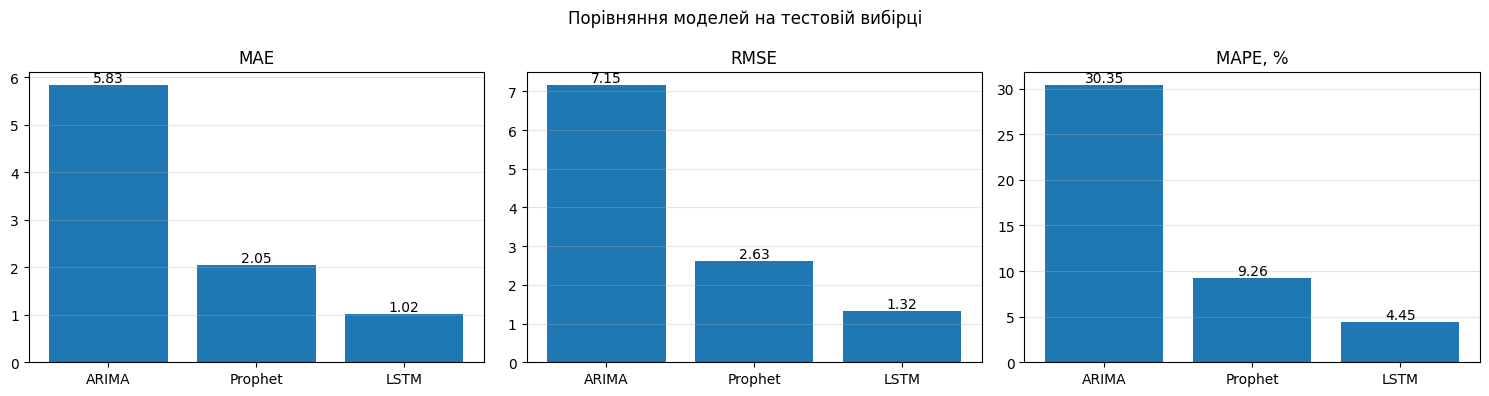

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, results.columns):
    ax.bar(results.index, results[metric])
    ax.set_title(metric)
    for i, v in enumerate(results[metric]):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.grid(alpha=0.3, axis="y")
plt.suptitle("Порівняння моделей на тестовій вибірці")
plt.tight_layout()
plt.show()

## Висновок

У роботі проаналізовано щоденні дані про середню температуру в Делі за 2013–2024 роки (4249 днів). Датасет містив 693 пропущені дати (≈16%, майже всі у 2013–2017 роках), які було заповнено часовою інтерполяцією, а тестова вибірка (останні 20%, 850 днів) складається майже повністю з реальних спостережень. EDA та автокореляційний аналіз показали яскраво виражену річну сезонність (ACF на лагу 365 ≈ 0,83 і ≈ −0,71 на лагу 182), стаціонарність ряду за тестом Дікі—Фуллера (p ≈ 0,017) та відсутність викидів за правилом 1,5·IQR для всього ряду.

За результатами порівняння на тестовій вибірці найкращі значення за всіма трьома метриками показала модель LSTM (MAE ≈ 1,02 °C, RMSE ≈ 1,32 °C, MAPE ≈ 4,4%), далі йде Prophet (MAE ≈ 2,06 °C, RMSE ≈ 2,64 °C, MAPE ≈ 9,3%) і ARIMA(3,0,1) (MAE ≈ 5,83 °C, RMSE ≈ 7,15 °C, MAPE ≈ 30,3%). Слабкий результат ARIMA пояснюється тим, що модель несезонна: на горизонті 850 днів її прогноз швидко збігається до середнього рівня (≈ 25,6 °C) і не відтворює річний цикл, а тест Люнга—Бокса на лагу 30 вказує на залишкову автокореляцію в залишках. Prophet, навпаки, явно моделює річну сезонність і при цьому прогнозує весь тестовий період, жодного разу не бачивши фактичних значень з нього. Перевагу LSTM слід інтерпретувати обережно: нейромережа прогнозує лише на один крок уперед за 30 фактичними попередніми днями, і її похибка практично збігається з наївним прогнозом «завтра як сьогодні» (MAE ≈ 0,94 °C), тобто модель переважно відтворює інерційність температури. Коли LSTM змушено прогнозувати весь тестовий період рекурсивно, її MAE зростає до ≈ 5,7 °C, що порівняно з ARIMA. Отже, формально найкращою є LSTM, але для довгострокового прогнозу без відомої історії найкращою є Prophet (у ≈ 2,8 раза точніша за ARIMA за MAE). Обмеженнями роботи є єдине train/test-розбиття, інтерполяція прогалин у тренувальній частині, відсутність підбору гіперпараметрів та випадковість навчання LSTM (за різних початкових значень MAE на один крок змінюється приблизно в межах 0,94–1,02 °C); поліпшити довгостроковий прогноз можна сезонними моделями (SARIMA з гармоніками Фур'є) або залученням додаткових ознак, таких як вологість чи тиск.